# Exploración de Datos Multivariados — Hospital 4
## Archivo 2 de 2: análisis (versión corregida)

**Grupo 4 — Jacob, Barzola, Henchoz**

> **Pregunta de investigación.** ¿Qué distingue a un paciente clasificado como de alto riesgo de uno de bajo riesgo en el Hospital 4, y cuánta de la información que la institución registra en cada control es realmente necesaria para establecer esa distinción?

**Entrada:** `dataset_limpio.csv`, generado por el archivo 1 (`01_limpieza`). Antes de ejecutar, subirlo al panel de archivos de Colab (carpeta `/content`).

**Salidas:** `tabla2_comparacion.csv`, `tabla4_hotelling.csv`, `tabla5_contingencia.csv`, `tabla9_perfiles.csv` y las figuras `figura01` a `figura13` en formato PNG.

| Sección del notebook | Sección del informe |
|---|---|
| 1. Paquetes, configuración y carga | 1 y 2 |
| 2. Comparación variable por variable | 4 (Tabla 2, Figuras 1 y 2) |
| 3. Las cinco variables en conjunto | 5 (Tablas 3 y 4, Figuras 3 a 6) |
| 4. Lo que no separa: categóricas y glucosa | 6 (Tabla 5, Figura 7) |
| 5. Estructura conjunta y componentes principales | 7 (Tablas 6 a 8, Figuras 8 a 11) |
| 6. El alto riesgo no es homogéneo | 8 (Tabla 9, Figuras 12 y 13) |

**Cambios respecto de la versión entregada**
- Visualización multivariada: dispersión tridimensional, coordenadas paralelas, perfiles multivariados, gráfico radial, diagramas de estrellas y caras de Chernoff.
- Contrastes: prueba de Wilcoxon-Mann-Whitney junto a la t de Welch, T² de Hotelling con su diagnóstico de normalidad (gráfico Q-Q y curtosis de Mardia) y prueba de Kruskal-Wallis entre los subgrupos del alto riesgo.
- Tablas de contingencia con porcentajes sobre el total, por fila y por columna.
- Histograma del índice de masa corporal con intervalos de 0,5 alineados con los cortes clínicos.
- El ACP de las cinco variables ya no se presenta como validación externa; la evidencia independiente de la selección es el ACP de control de catorce variables.

## 1. Paquetes, configuración y carga de datos
### 1.1. Paquetes
Se usan los mismos paquetes que en el Colab de la Unidad 3 (gráficos multivariados): `scatterplot3d`, `GGally`, `aplpack`, `car` y `Hotelling`. Cada uno se instala sólo si falta.

In [ ]:
paquetes <- c("ggplot2", "dplyr", "tidyr", "GGally", "scatterplot3d", "aplpack", "car", "Hotelling")
# GGally requiere una versión reciente de ggplot2: se actualiza antes de cargar nada
if (!("ggplot2" %in% rownames(installed.packages())) || packageVersion("ggplot2") < "3.5.2") {
  install.packages("ggplot2")
}
instalados <- rownames(installed.packages())
for (paq in paquetes) {
  if (!(paq %in% instalados)) install.packages(paq)
}
suppressPackageStartupMessages({
  library(ggplot2); library(dplyr); library(tidyr); library(GGally)
  library(scatterplot3d); library(aplpack); library(car); library(Hotelling)
})
options(width = 150)
cat("Paquetes cargados:", paste(paquetes, collapse = ", "), "\n")

Paquetes cargados: ggplot2, dplyr, tidyr, GGally, scatterplot3d, aplpack, car, Hotelling 


### 1.2. Configuración y funciones auxiliares
- `magnitud_efecto()`: diferencia de medias dividida por el desvío estándar agrupado (d de Cohen).
- `levene()`: prueba de Levene de `car` centrada en la mediana (versión de Brown-Forsythe).
- `kmo()`: índice de Kaiser-Meyer-Olkin global y por variable, calculado a partir de la matriz de correlación.
- `guardar()` y `guardar_base()`: muestran cada figura en el notebook y la guardan en PNG a 300 dpi.

In [ ]:
ALTO <- "#eb6834"   # alto riesgo
BAJO <- "#2a78d6"   # bajo riesgo
GRIS <- "#9a9995"
tema <- theme_minimal(base_size = 10) +
  theme(panel.grid.minor = element_blank(),
        plot.title = element_text(face = "bold", size = 11))
con_coma <- function(x) sub(".", ",", as.character(x), fixed = TRUE)

guardar <- function(g, archivo, an = 16, al = 10) {          # figuras de ggplot2
  options(repr.plot.width = an / 2.54 * 1.25, repr.plot.height = al / 2.54 * 1.25)
  print(g)
  ggsave(archivo, g, width = an, height = al, units = "cm", dpi = 300, bg = "white")
  cat("Figura guardada:", archivo, "\n")
}
guardar_base <- function(archivo, dibujar, an = 16, al = 12) {  # figuras de R base
  options(repr.plot.width = an / 2.54 * 1.25, repr.plot.height = al / 2.54 * 1.25)
  dibujar()
  png(archivo, width = an, height = al, units = "cm", res = 300)
  dibujar()
  invisible(dev.off())
  cat("Figura guardada:", archivo, "\n")
}

magnitud_efecto <- function(a, b) {
  s <- sqrt(((length(a) - 1) * var(a) + (length(b) - 1) * var(b)) /
            (length(a) + length(b) - 2))
  (mean(a) - mean(b)) / s
}

levene <- function(x, g) {
  r <- leveneTest(y ~ grupo, data = data.frame(y = x, grupo = factor(g)))
  c(F = r[1, "F value"], p = r[1, "Pr(>F)"])
}

kmo <- function(R) {
  R_inv <- solve(R)
  parcial <- -R_inv / sqrt(outer(diag(R_inv), diag(R_inv)))
  diag(parcial) <- 1
  num <- sum(R^2) - ncol(R)
  global <- num / (num + sum(parcial^2) - ncol(R))
  por_variable <- sapply(seq_len(ncol(R)), function(i) {
    a <- sum(R[i, ]^2) - 1
    a / (a + sum(parcial[i, ]^2) - 1)
  })
  names(por_variable) <- colnames(R)
  list(global = global, por_variable = por_variable, parcial = parcial)
}

### 1.3. Carga del dataset depurado

In [ ]:
d <- read.csv("dataset_limpio.csv", stringsAsFactors = FALSE, encoding = "UTF-8",
              na.strings = c("", "NA"))      # celdas vacías y "NA" se leen como dato faltante
cat("Registros:", nrow(d), "| Variables:", ncol(d), "\n")

Registros: 13331 | Variables: 36 


**Trazabilidad de la depuración (informe, sección 1.1).** La limpieza convierte a dato faltante los códigos de error con formato `ERROR_nnn`. Esta celda los cuenta en la base original, si `Hospital_4.csv` también está en `/content`; la columna vacía que se elimina en la limpieza sólo contenía códigos de este tipo.

In [ ]:
if (file.exists("Hospital_4.csv")) {
  original <- read.csv("Hospital_4.csv", quote = "\"", fill = TRUE, stringsAsFactors = FALSE)
  errores <- sapply(original, function(x) sum(grepl("^error_", tolower(trimws(as.character(x))))))
  print(errores[errores > 0])
  cat("Códigos de error en las variables que se conservan:",
      sum(errores[names(errores) != "Empty_Int_Column"]), "\n")
} else {
  cat("Para reproducir este conteo, subir también Hospital_4.csv a /content\n")
}

       Timestamp           Gender    Risk.Category Empty_Int_Column 
             479              487              486              498 
Códigos de error en las variables que se conservan: 1452 


### 1.4. Subconjuntos de variables
- **`discriminantes`**: las cinco variables que separan los grupos de riesgo (se justifica en la sección 2).
- **`no_discriminantes`**: seis variables de contraste que no los separan.
- **`todas_numericas`**: las dieciocho variables cuantitativas que el hospital registra en cada control.
- **`control_14`**: las dieciocho sin peso y altura (componentes del cálculo del IMC) ni presión arterial media y presión de pulso (se calculan a partir de la sistólica y la diastólica).

In [ ]:
discriminantes <- c("trigliceridos", "colesterol", "frecuencia_cardiaca",
                    "creatinina", "imc_derivado")
no_discriminantes <- c("presion_arterial_sistolica", "presion_arterial_diastolica",
                       "saturacion_oxigeno", "frecuencia_respiratoria",
                       "temperatura_corporal", "vfc_derivada")
todas_numericas <- c(discriminantes, "glucosa", no_discriminantes,
                     "pam_derivada", "presion_pulso_derivada", "hemoglobina",
                     "edad", "peso_kg", "altura_m")
control_14 <- setdiff(todas_numericas,
                      c("peso_kg", "altura_m", "pam_derivada", "presion_pulso_derivada"))
resto_13 <- setdiff(todas_numericas, discriminantes)
categoricas <- c("genero", "diagnostico", "estado_fumador",
                 "nivel_actividad_fisica", "region", "nivel_socioeconomico",
                 "ocupacion", "turno", "estacion", "grupo_etario")

etiquetas <- c(trigliceridos = "Triglicéridos", colesterol = "Colesterol",
  frecuencia_cardiaca = "Frecuencia cardíaca", creatinina = "Creatinina",
  imc_derivado = "IMC", glucosa = "Glucosa",
  presion_arterial_sistolica = "Presión sistólica",
  presion_arterial_diastolica = "Presión diastólica",
  saturacion_oxigeno = "Saturación O2", frecuencia_respiratoria = "Frec. respiratoria",
  temperatura_corporal = "Temperatura", vfc_derivada = "VFC",
  pam_derivada = "Presión arterial media", presion_pulso_derivada = "Presión de pulso",
  hemoglobina = "Hemoglobina", edad = "Edad", peso_kg = "Peso", altura_m = "Altura")
cat("Discriminantes:", length(discriminantes), "| Total cuantitativas:", length(todas_numericas),
    "| Control:", length(control_14), "| Restantes:", length(resto_13), "\n")

Discriminantes: 5 | Total cuantitativas: 18 | Control: 14 | Restantes: 13 


### 1.5. Variables nuevas
Categorías clínicas del IMC y de edad, las cinco discriminantes estandarizadas (media 0, desvío 1), la distancia de Mahalanobis de cada paciente al centro de la nube y el factor de riesgo con etiquetas para los gráficos.

In [ ]:
d$imc_cat <- cut(d$imc_derivado, breaks = c(-Inf, 18.5, 25, 30, Inf),
                 labels = c("bajo peso", "normal", "sobrepeso", "obesidad"), right = FALSE)
d$grupo_etario <- cut(d$edad, breaks = c(17, 39, 64, Inf),
                      labels = c("18-39", "40-64", "65 o mas"))
for (v in discriminantes) {
  d[[paste0("z_", v)]] <- (d[[v]] - mean(d[[v]])) / sd(d[[v]])
}
Z <- as.matrix(d[, paste0("z_", discriminantes)])
d$d_mahalanobis <- sqrt(mahalanobis(Z, colMeans(Z), cov(Z)))
umbral_mahal <- sqrt(qchisq(0.999, df = length(discriminantes)))

alto <- d$categoria_riesgo == "alto_riesgo"
bajo <- d$categoria_riesgo == "bajo_riesgo"
d$riesgo <- factor(d$categoria_riesgo, levels = c("alto_riesgo", "bajo_riesgo"),
                   labels = c("Alto riesgo", "Bajo riesgo"))
print(table(d$riesgo))


Alto riesgo Bajo riesgo 
       7012        6319 


## 2. Comparación variable por variable (informe, sección 4)
**Criterio de relevancia: la magnitud del efecto d, no el valor p.** Con 13.331 registros casi cualquier diferencia resulta significativa; d expresa la distancia entre las medias en desvíos estándar y no depende del tamaño de muestra. Umbral convencional: |d| ≥ 0,20.

**Contrastes según sus supuestos.** La prueba de Levene evalúa si las varianzas de los grupos son iguales. Como las rechaza en las variables discriminantes, las medias se comparan con la prueba t de Welch (la opción por defecto de `t.test`, que no supone varianzas iguales) y se verifican con la prueba de Wilcoxon-Mann-Whitney, que no supone normalidad.

### 2.1. Tabla 2 del informe

In [ ]:
tabla2 <- data.frame()
for (v in todas_numericas) {
  a <- d[[v]][alto]; b <- d[[v]][bajo]
  tt <- t.test(a, b)                     # t de Welch
  lv <- levene(d[[v]], d$categoria_riesgo)
  wx <- wilcox.test(a, b)                # Wilcoxon-Mann-Whitney
  tabla2 <- rbind(tabla2, data.frame(
    variable   = v,
    media_alto = round(mean(a), 2), sd_alto = round(sd(a), 2),
    media_bajo = round(mean(b), 2), sd_bajo = round(sd(b), 2),
    d          = round(magnitud_efecto(a, b), 3),
    t          = round(unname(tt$statistic), 2),
    p_welch    = signif(tt$p.value, 3),
    levene_F   = round(unname(lv["F"]), 1),
    p_levene   = signif(unname(lv["p"]), 3),
    p_wilcoxon = signif(wx$p.value, 3)))
}
tabla2 <- tabla2[order(-abs(tabla2$d)), ]
rownames(tabla2) <- NULL
print(tabla2)
write.csv(tabla2, "tabla2_comparacion.csv", row.names = FALSE)
cat("\nVariables discriminantes (|d| >= 0,20):",
    paste(tabla2$variable[abs(tabla2$d) >= 0.2], collapse = ", "), "\n")

                      variable media_alto sd_alto media_bajo sd_bajo      d      t  p_welch levene_F  p_levene p_wilcoxon
1                trigliceridos     237.95   66.20     155.12   49.03  1.411  82.61 0.00e+00    662.5 1.26e-142   0.00e+00
2                   colesterol     233.80   39.02     190.03   30.13  1.248  72.88 0.00e+00    382.6  5.13e-84   0.00e+00
3          frecuencia_cardiaca      83.63   12.23      74.99    8.98  0.798  46.75 0.00e+00    710.0 1.88e-152   0.00e+00
4                   creatinina       1.43    0.45       1.10    0.50  0.699  40.08 0.00e+00      7.1  7.60e-03   0.00e+00
5                 imc_derivado      25.84    8.24      24.00    3.12  0.290  17.38 1.39e-66   8917.1  0.00e+00   0.00e+00
6                     altura_m       1.74    0.15       1.76    0.13 -0.176 -10.19 2.59e-24    199.1  6.86e-45   1.19e-23
7                      peso_kg      75.24   15.92      74.74   12.75  0.034   1.99 4.63e-02    826.6 2.05e-176   4.85e-02
8      frecuencia_respir

### 2.2. Robustez de la selección
El corte en 0,20 es una convención. La selección es sólida si no hay ninguna variable ambigua cerca del corte y si no depende de suponer varianzas iguales: se recalcula d con la varianza promedio de los dos grupos.

In [ ]:
abs_d <- abs(tabla2$d)
for (k in 5:7) cat(sprintf("Posición %d: %-20s |d| = %.3f\n", k, tabla2$variable[k], abs_d[k]))
cat("Cualquier umbral mayor que", abs_d[6], "y menor o igual que", abs_d[5],
    "selecciona las mismas cinco variables\n")
cat("d de las trece restantes: entre", min(tabla2$d[6:18]), "y", max(tabla2$d[6:18]), "\n")
cat("La séptima magnitud es el", round(100 * abs_d[7] / abs_d[6], 1), "% de la sexta\n")

d_var_promedio <- sapply(discriminantes, function(v) {
  a <- d[[v]][alto]; b <- d[[v]][bajo]
  (mean(a) - mean(b)) / sqrt((var(a) + var(b)) / 2)
})
cat("\nd recalculada con la varianza promedio de los dos grupos:\n")
print(round(d_var_promedio, 3))

Posición 5: imc_derivado         |d| = 0.290
Posición 6: altura_m             |d| = 0.176
Posición 7: peso_kg              |d| = 0.034
Cualquier umbral mayor que 0.176 y menor o igual que 0.29 selecciona las mismas cinco variables
d de las trece restantes: entre -0.176 y 0.034 
La séptima magnitud es el 19.3 % de la sexta

d recalculada con la varianza promedio de los dos grupos:
      trigliceridos          colesterol frecuencia_cardiaca          creatinina        imc_derivado 
              1.422               1.256               0.805               0.697               0.296 


### 2.3. Síntesis de los contrastes

In [ ]:
cat("Levene rechaza varianzas iguales (p < 0,05) en:",
    paste(tabla2$variable[tabla2$p_levene < 0.05], collapse = ", "), "\n\n")
cat("Welch, diferencias significativas (p < 0,05):",
    paste(tabla2$variable[tabla2$p_welch < 0.05], collapse = ", "), "\n\n")
cat("Wilcoxon, diferencias significativas (p < 0,05):",
    paste(tabla2$variable[tabla2$p_wilcoxon < 0.05], collapse = ", "), "\n\n")
cat("Mismo conjunto en ambas pruebas:",
    setequal(tabla2$variable[tabla2$p_welch < 0.05], tabla2$variable[tabla2$p_wilcoxon < 0.05]), "\n")
no_sig <- tabla2$p_welch[tabla2$p_welch >= 0.05]
cat("Valores p de las once no significativas: entre", min(no_sig), "y", max(no_sig), "\n")
cat("t de Welch en las cinco discriminantes: entre", min(tabla2$t[1:5]), "y", max(tabla2$t[1:5]), "\n")

Levene rechaza varianzas iguales (p < 0,05) en: trigliceridos, colesterol, frecuencia_cardiaca, creatinina, imc_derivado, altura_m, peso_kg 

Welch, diferencias significativas (p < 0,05): trigliceridos, colesterol, frecuencia_cardiaca, creatinina, imc_derivado, altura_m, peso_kg 

Wilcoxon, diferencias significativas (p < 0,05): trigliceridos, colesterol, frecuencia_cardiaca, creatinina, imc_derivado, altura_m, peso_kg 

Mismo conjunto en ambas pruebas: TRUE 
Valores p de las once no significativas: entre 0.227 y 0.992 
t de Welch en las cinco discriminantes: entre 17.38 y 82.61 


### 2.4. Figura 1 — Magnitud del efecto de las dieciocho variables

Figura guardada: figura01_ranking.png 


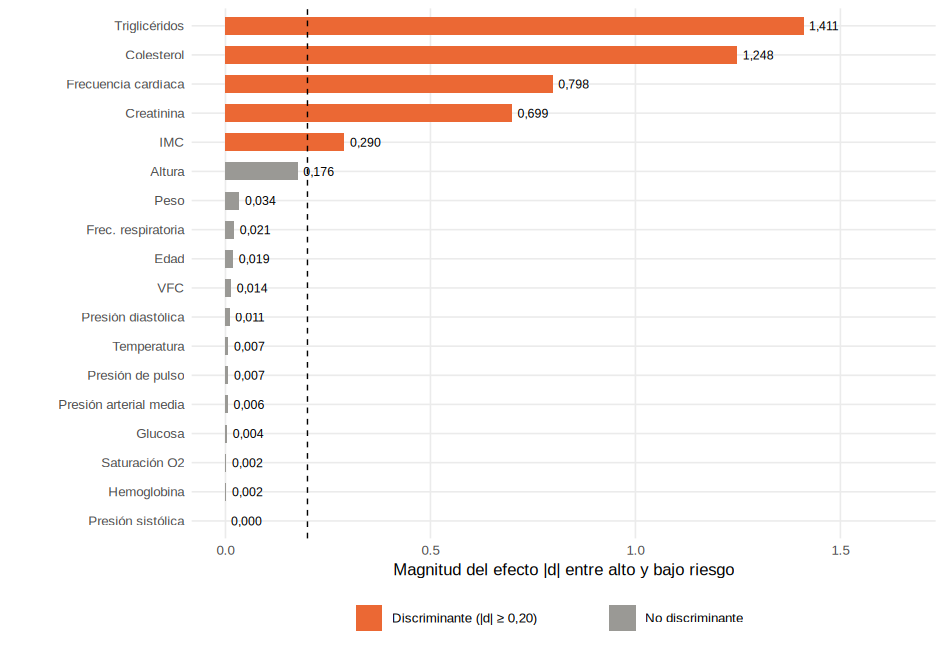

In [ ]:
f1 <- tabla2
f1$abs_d <- abs(f1$d)
f1$nombre <- factor(etiquetas[f1$variable], levels = rev(etiquetas[f1$variable]))
f1$grupo <- ifelse(f1$abs_d >= 0.2, "Discriminante (|d| ≥ 0,20)", "No discriminante")
g1 <- ggplot(f1, aes(x = nombre, y = abs_d, fill = grupo)) +
  geom_col(width = 0.62) +
  geom_hline(yintercept = 0.2, linetype = "dashed", linewidth = 0.4) +
  geom_text(aes(label = format(round(abs_d, 3), decimal.mark = ",")), hjust = -0.18, size = 2.6) +
  scale_fill_manual(values = c("Discriminante (|d| ≥ 0,20)" = ALTO, "No discriminante" = GRIS)) +
  coord_flip() + expand_limits(y = 1.65) +
  labs(x = NULL, y = "Magnitud del efecto |d| entre alto y bajo riesgo", fill = NULL) +
  tema + theme(legend.position = "bottom")
guardar(g1, "figura01_ranking.png", 16, 11)

### 2.5. Figura 2 — Distribución por grupo de las cinco discriminantes y dos variables de contraste

Figura guardada: figura02_boxplots.png 


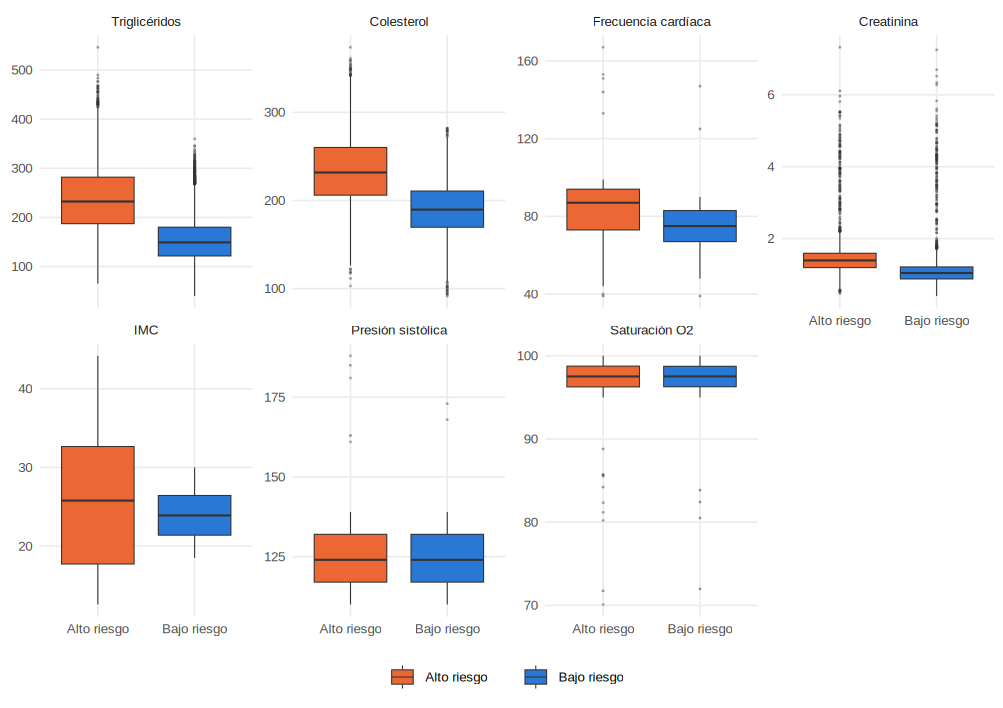

In [ ]:
vars_f2 <- c(discriminantes, "presion_arterial_sistolica", "saturacion_oxigeno")
largo <- do.call(rbind, lapply(vars_f2, function(v)
  data.frame(variable = unname(etiquetas[v]), valor = d[[v]], riesgo = d$riesgo)))
largo$variable <- factor(largo$variable, levels = etiquetas[vars_f2])
g2 <- ggplot(largo, aes(x = riesgo, y = valor, fill = riesgo)) +
  geom_boxplot(outlier.size = 0.25, outlier.alpha = 0.3, linewidth = 0.3) +
  facet_wrap(~ variable, scales = "free_y", nrow = 2) +
  scale_fill_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  labs(x = NULL, y = NULL, fill = NULL) + tema + theme(legend.position = "bottom")
guardar(g2, "figura02_boxplots.png", 17, 12)

## 3. Las cinco variables en conjunto (informe, sección 5)
La comparación de a una variable deja abiertas dos preguntas: si las cinco dicen cosas distintas o se superponen, y cómo se distribuyen los pacientes cuando se las mira a la vez. Cada representación se eligió para responder una pregunta (Tabla 3 del informe):

| Representación | Pregunta que responde | Por qué es la adecuada |
|---|---|---|
| Dispersión tridimensional (Fig. 3) | ¿Cómo se ubican los pacientes en las tres variables del eje principal? | Muestra la nube completa y su solapamiento; deja ver subgrupos que la media esconde. |
| Coordenadas paralelas (Fig. 4) | ¿Cómo se comporta cada paciente en las cinco variables a la vez? | Representa individuos, no promedios, en más de tres dimensiones. |
| Perfiles multivariados (Fig. 5a) | ¿En qué variables y por cuánto difieren las medias? | Permite leer cada media y la distancia entre perfiles variable por variable. |
| Gráfico radial (Fig. 5b) | ¿Qué forma tiene el perfil de cada grupo? | Resume en una figura el tamaño y la forma del perfil. |
| Estrellas y caras de Chernoff (Fig. 13) | ¿Qué distingue a los subgrupos del alto riesgo? | Son adecuadas para pocos casos: los centros de cuatro grupos (sección 6). |

### 3.1. Figura 3 — Dispersión tridimensional de triglicéridos, colesterol e IMC
Se dibuja uno de cada cuatro pacientes para que la nube sea legible; los círculos con borde negro son los centros de cada grupo calculados con todos los pacientes.

Pacientes dibujados: 3333 
       riesgo trigliceridos colesterol imc_derivado
1 Alto riesgo      237.9529   233.8028     25.83664
2 Bajo riesgo      155.1217   190.0320     23.99606
Figura guardada: figura03_dispersion_3d.png 


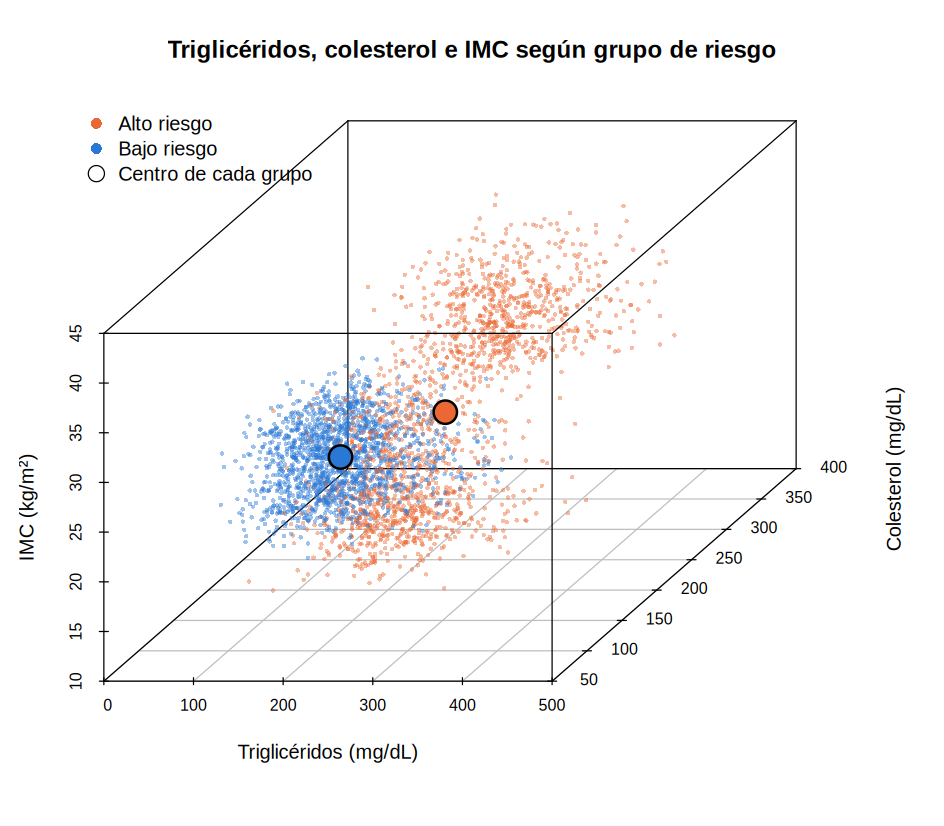

In [ ]:
sub4 <- d[seq(1, nrow(d), by = 4), ]
cat("Pacientes dibujados:", nrow(sub4), "\n")
centros_3d <- aggregate(d[, c("trigliceridos", "colesterol", "imc_derivado")],
                        by = list(riesgo = d$riesgo), FUN = mean)
print(centros_3d)
colores_3d <- ifelse(sub4$categoria_riesgo == "alto_riesgo",
                     adjustcolor(ALTO, alpha.f = 0.45), adjustcolor(BAJO, alpha.f = 0.45))

dibujar_3d <- function() {
  s3d <- scatterplot3d(
    x = sub4$trigliceridos, y = sub4$colesterol, z = sub4$imc_derivado,
    color = colores_3d, pch = 16, cex.symbols = 0.5, angle = 55,
    main = "Triglicéridos, colesterol e IMC según grupo de riesgo",
    xlab = "Triglicéridos (mg/dL)", ylab = "Colesterol (mg/dL)", zlab = "IMC (kg/m²)")
  s3d$points3d(centros_3d$trigliceridos, centros_3d$colesterol, centros_3d$imc_derivado,
               pch = 21, bg = c(ALTO, BAJO), col = "black", cex = 2.6, lwd = 2)
  legend("topleft", legend = c("Alto riesgo", "Bajo riesgo", "Centro de cada grupo"),
         col = c(ALTO, BAJO, "black"), pch = c(16, 16, 21), pt.bg = c(NA, NA, "white"),
         pt.cex = c(1.2, 1.2, 1.8), bty = "n")
}
guardar_base("figura03_dispersion_3d.png", dibujar_3d, 16, 14)

**¿Qué tan poblada está la zona del centro de cada grupo?** Sobre las tres variables estandarizadas, se cuenta cuántos pacientes de cada grupo están a una distancia menor que 0,5 del centro de su propio grupo.

In [ ]:
Z3 <- scale(d[, c("trigliceridos", "colesterol", "imc_derivado")])
for (g in c("alto_riesgo", "bajo_riesgo")) {
  m <- d$categoria_riesgo == g
  centro <- colMeans(Z3[m, ])
  distancia <- sqrt(rowSums(sweep(Z3[m, ], 2, centro)^2))
  cat(g, ": pacientes a menos de 0,5 del centro propio =", sum(distancia < 0.5), "de", sum(m),
      "(", round(100 * mean(distancia < 0.5), 1), "% )\n")
}

alto_riesgo : pacientes a menos de 0,5 del centro propio = 97 de 7012 ( 1.4 % )
bajo_riesgo : pacientes a menos de 0,5 del centro propio = 616 de 6319 ( 9.7 % )


### 3.2. Figura 4 — Coordenadas paralelas
Cada línea es un paciente y cada eje una variable estandarizada. Se dibuja uno de cada diez pacientes y los valores se truncan en ±3 desvíos para que los casos extremos no compriman el gráfico. Como las variables ya están estandarizadas, se usa `scale = "globalminmax"` (sin reescalar).

Pacientes dibujados: 1334 
Figura guardada: figura04_coordenadas_paralelas.png 
Pacientes con frecuencia cardíaca mayor que 90: alto riesgo = 3018 | bajo riesgo = 2 


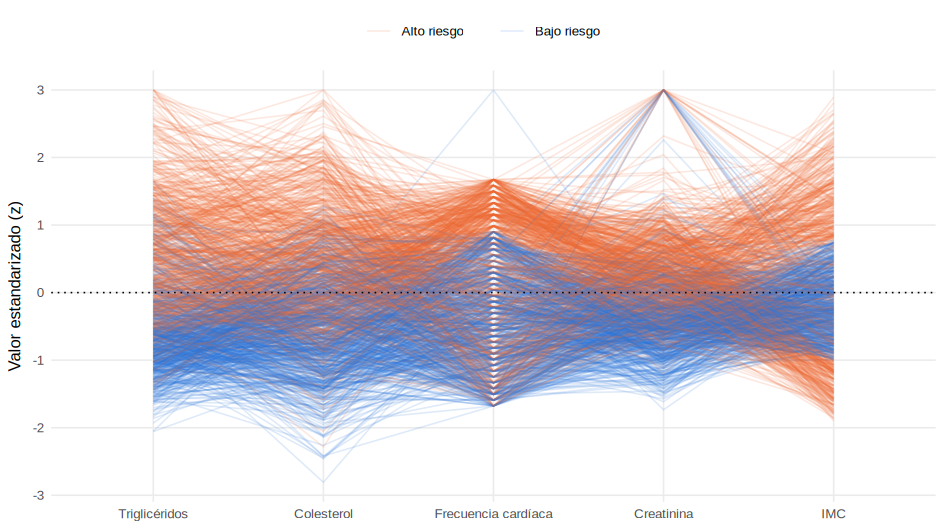

In [ ]:
sub10 <- d[seq(1, nrow(d), by = 10), ]
z_par <- as.data.frame(lapply(discriminantes, function(v)
  pmin(pmax((sub10[[v]] - mean(d[[v]])) / sd(d[[v]]), -3), 3)))
names(z_par) <- etiquetas[discriminantes]
z_par$riesgo <- sub10$riesgo
cat("Pacientes dibujados:", nrow(z_par), "\n")

g4 <- ggparcoord(z_par, columns = 1:5, groupColumn = "riesgo", scale = "globalminmax",
                 alphaLines = 0.15, showPoints = FALSE) +
  scale_colour_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  geom_hline(yintercept = 0, linetype = "dotted") +
  labs(x = NULL, y = "Valor estandarizado (z)", colour = NULL) +
  tema + theme(legend.position = "top")
guardar(g4, "figura04_coordenadas_paralelas.png", 16, 9)

cat("Pacientes con frecuencia cardíaca mayor que 90: alto riesgo =",
    sum(alto & d$frecuencia_cardiaca > 90), "| bajo riesgo =", sum(bajo & d$frecuencia_cardiaca > 90), "\n")

### 3.3. Figura 5a — Perfiles multivariados
Medias estandarizadas de cada grupo, unidas variable por variable (`ggparcoord` sobre las medias, como en el Colab de la unidad).

       riesgo Triglicéridos Colesterol Frecuencia cardíaca Creatinina        IMC
1 Alto riesgo     0.5468373  0.5019402           0.3515617  0.3126495  0.1360126
2 Bajo riesgo    -0.6068086 -0.5569876          -0.3901173 -0.3469375 -0.1509290

Distancia entre perfiles (alto menos bajo), en desvíos:
      Triglicéridos          Colesterol Frecuencia cardíaca          Creatinina                 IMC 
               1.15                1.06                0.74                0.66                0.29 
Figura guardada: figura05a_perfiles.png 


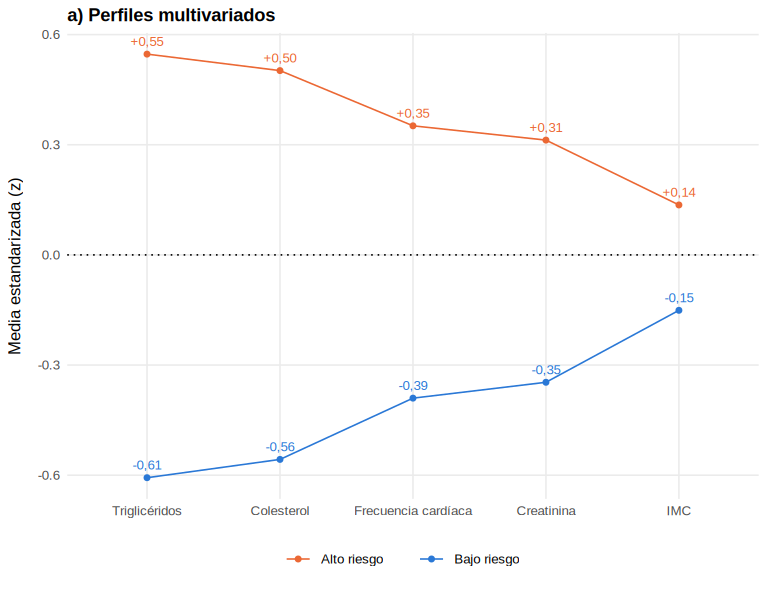

In [ ]:
Zdf <- as.data.frame(Z)
names(Zdf) <- etiquetas[discriminantes]
Zdf$riesgo <- d$riesgo

# Calculate group-wise means using highly robust base R aggregate
perfil_medio <- aggregate(. ~ riesgo, data = Zdf, FUN = mean)
print(perfil_medio)

brecha <- unlist(perfil_medio[perfil_medio$riesgo == "Alto riesgo", -1]) -
          unlist(perfil_medio[perfil_medio$riesgo == "Bajo riesgo", -1])
cat("\nDistancia entre perfiles (alto menos bajo), en desvíos:\n"); print(round(brecha, 2))

g5a <- ggparcoord(perfil_medio, columns = 2:6, groupColumn = "riesgo",
                  showPoints = TRUE, scale = "globalminmax") +
  geom_hline(yintercept = 0, linetype = "dotted") +
  geom_text(aes(label = con_coma(sprintf("%+.2f", value))), vjust = -0.9, size = 2.8,
            show.legend = FALSE) +
  scale_colour_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  labs(x = NULL, y = "Media estandarizada (z)", colour = NULL,
       title = "a) Perfiles multivariados") +
  tema + theme(legend.position = "bottom")
guardar(g5a, "figura05a_perfiles.png", 13, 10)

### 3.4. Figura 5b — Gráfico radial
Las mismas medias estandarizadas en ejes radiales. El centro del gráfico corresponde a z = −0,9 y el círculo negro marca la media de la base completa (z = 0). Los polígonos se construyen en coordenadas cartesianas para que sus lados sean rectos y se cierren.

Figura guardada: figura05b_radial.png 


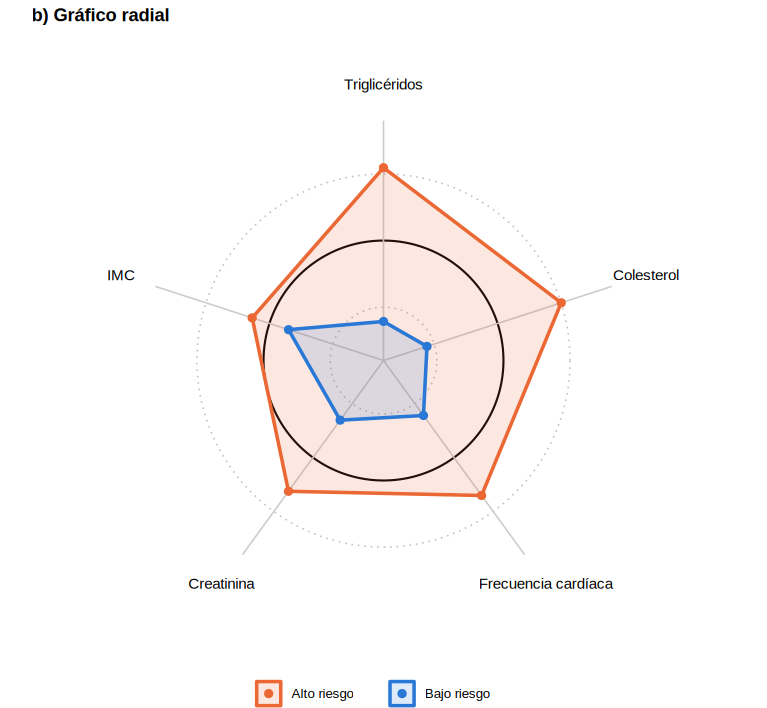

In [ ]:
radial <- perfil_medio |>
  pivot_longer(-riesgo, names_to = "variable", values_to = "z")
radial$k <- match(radial$variable, etiquetas[discriminantes])
angulo <- function(k) pi / 2 - 2 * pi * (k - 1) / 5      # primer eje arriba, sentido horario
centro_r <- -0.9
radial$x <- (radial$z - centro_r) * cos(angulo(radial$k))
radial$y <- (radial$z - centro_r) * sin(angulo(radial$k))
radial <- radial[order(radial$riesgo, radial$k), ]

giro <- seq(0, 2 * pi, length.out = 200)
circulos <- do.call(rbind, lapply(c(-0.5, 0, 0.5), function(zc)
  data.frame(nivel = zc, x = (zc - centro_r) * cos(giro), y = (zc - centro_r) * sin(giro))))
ejes <- data.frame(x = 1.8 * cos(angulo(1:5)), y = 1.8 * sin(angulo(1:5)),
                   nombre = etiquetas[discriminantes])

g5b <- ggplot() +
  geom_path(data = subset(circulos, nivel != 0), aes(x, y, group = nivel),
            colour = "grey75", linetype = "dotted") +
  geom_path(data = subset(circulos, nivel == 0), aes(x, y), colour = "black", linewidth = 0.6) +
  geom_segment(data = ejes, aes(x = 0, y = 0, xend = x, yend = y), colour = "grey80") +
  geom_polygon(data = radial, aes(x, y, group = riesgo, colour = riesgo, fill = riesgo),
               alpha = 0.15, linewidth = 1) +
  geom_point(data = radial, aes(x, y, colour = riesgo), size = 2) +
  geom_text(data = ejes, aes(x = 1.15 * x, y = 1.15 * y, label = nombre), size = 3.2) +
  scale_colour_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  scale_fill_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  coord_equal(xlim = c(-2.4, 2.4), ylim = c(-2.1, 2.3)) +
  labs(title = "b) Gráfico radial", colour = NULL, fill = NULL) +
  theme_void(base_size = 10) +
  theme(legend.position = "bottom", plot.title = element_text(face = "bold", size = 11))
guardar(g5b, "figura05b_radial.png", 13, 12)

### 3.5. Tabla 4 — Contraste multivariado de medias (T² de Hotelling)
H0: los vectores de medias de los dos grupos son iguales. El estadístico se construye con la distancia de Mahalanobis entre los centros, calculada con la matriz de covarianzas común:

T² = n₁·n₂ / (n₁ + n₂) · D²   y   F = (n₁ + n₂ − p − 1) / (p·(n₁ + n₂ − 2)) · T², con p y n₁ + n₂ − p − 1 grados de libertad.

Se contrasta el conjunto de las cinco discriminantes y el de las trece restantes.

In [ ]:
hotelling_manual <- function(vars) {
  Xa <- as.matrix(d[alto, vars]); Xb <- as.matrix(d[bajo, vars])
  n1 <- nrow(Xa); n2 <- nrow(Xb); p <- length(vars)
  S_comun <- ((n1 - 1) * cov(Xa) + (n2 - 1) * cov(Xb)) / (n1 + n2 - 2)
  dif <- colMeans(Xa) - colMeans(Xb)
  D2 <- as.numeric(t(dif) %*% solve(S_comun) %*% dif)
  T2 <- n1 * n2 / (n1 + n2) * D2
  F_est <- (n1 + n2 - p - 1) / (p * (n1 + n2 - 2)) * T2
  gl2 <- n1 + n2 - p - 1
  data.frame(variables = p, D_Mahalanobis = round(sqrt(D2), 3), T2 = round(T2, 1),
             F = round(F_est, 1), gl1 = p, gl2 = gl2,
             p_valor = signif(pf(F_est, p, gl2, lower.tail = FALSE), 3))
}
tabla4 <- rbind(cbind(conjunto = "5 discriminantes", hotelling_manual(discriminantes)),
                cbind(conjunto = "13 restantes", hotelling_manual(resto_13)))
print(tabla4)
write.csv(tabla4, "tabla4_hotelling.csv", row.names = FALSE)
cat("\nLa distancia de las cinco es", round(tabla4$D_Mahalanobis[1] / tabla4$D_Mahalanobis[2], 1),
    "veces la de las trece restantes\n")

          conjunto variables D_Mahalanobis      T2      F gl1   gl2  p_valor
1 5 discriminantes         5         2.218 16350.0 3269.0   5 13325 0.00e+00
2     13 restantes        13         0.183   111.9    8.6  13 13317 1.01e-17

La distancia de las cinco es 12.1 veces la de las trece restantes


Verificación con el paquete `Hotelling` de la cursada. Sin permutaciones, el paquete informa como estadístico de prueba la T² sin escalar, que debe coincidir con la columna T2 de la tabla anterior; multiplicada por el factor `m` da la F.

In [ ]:
res_hot <- tryCatch(
  hotelling.test(cbind(trigliceridos, colesterol, frecuencia_cardiaca, creatinina, imc_derivado) ~ riesgo,
                 data = d),
  error = function(e) { cat("hotelling.test no pudo ejecutarse:", conditionMessage(e), "\n"); NULL })
if (!is.null(res_hot)) {
  print(res_hot)
  cat("F = m · T² =", round(res_hot$stats$m * res_hot$stats$statistic, 1), "\n")
}

Test stat:  16350 
Numerator df:  5 
Denominator df:  13325 
P-value:  0 
F = m · T² = 3269 


### 3.6. Figura 6 — Supuesto de normalidad multivariante
Bajo normalidad multivariante, las distancias de Mahalanobis al cuadrado siguen una chi-cuadrado con 5 grados de libertad. El gráfico Q-Q las compara con esos cuantiles. Se calcula además el coeficiente de curtosis multivariante de Mardia (b₂), cuyo valor esperado bajo normalidad es p(p + 2) = 35.

> `psych::mardia()` construye una matriz de n × n (13.331 × 13.331, más de 1,4 GB), por eso b₂ se calcula directamente con su fórmula: el promedio de las distancias de Mahalanobis al cuadrado elevadas al cuadrado, con la covarianza de máxima verosimilitud.

Percentiles 50, 90 y 99 de D²: 3.83 8.16 33.01 
Esperados bajo normalidad:      4.35 9.24 15.09 
Figura guardada: figura06_qq_mahalanobis.png 
Curtosis multivariante de Mardia: b2 = 65.06 | esperado = 35 | z = 207.4 | p = 0 


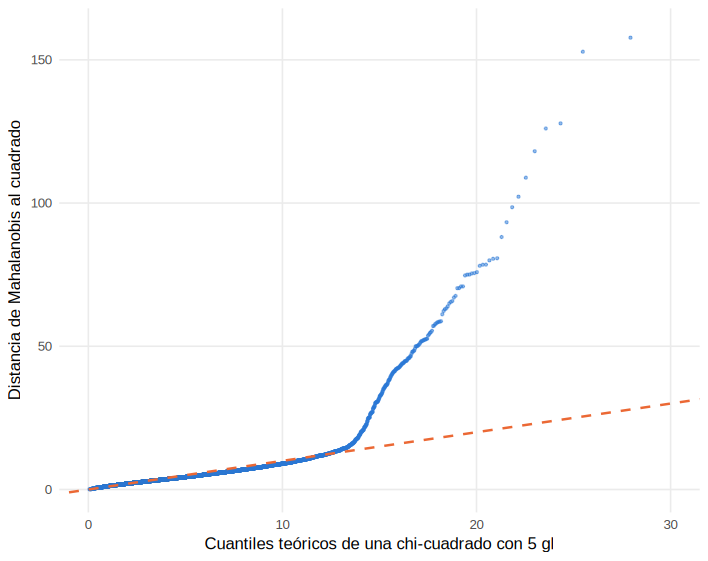

In [ ]:
n <- nrow(d); p <- length(discriminantes)
d2 <- d$d_mahalanobis^2
cat("Percentiles 50, 90 y 99 de D²:", round(quantile(d2, c(0.5, 0.9, 0.99)), 2), "\n")
cat("Esperados bajo normalidad:     ", round(qchisq(c(0.5, 0.9, 0.99), p), 2), "\n")

f6 <- data.frame(teorico = qchisq(ppoints(n), df = p), observado = sort(d2))
g6 <- ggplot(f6, aes(teorico, observado)) +
  geom_point(size = 0.6, alpha = 0.5, colour = BAJO) +
  geom_abline(intercept = 0, slope = 1, colour = ALTO, linetype = "dashed", linewidth = 0.7) +
  coord_cartesian(xlim = c(0, 30), ylim = c(0, 160)) +
  labs(x = "Cuantiles teóricos de una chi-cuadrado con 5 gl",
       y = "Distancia de Mahalanobis al cuadrado") + tema
guardar(g6, "figura06_qq_mahalanobis.png", 12, 9.5)

S_mv <- cov(Z) * (n - 1) / n
b2 <- mean(mahalanobis(Z, colMeans(Z), S_mv)^2)
z_b2 <- (b2 - p * (p + 2)) / sqrt(8 * p * (p + 2) / n)
cat("Curtosis multivariante de Mardia: b2 =", round(b2, 2), "| esperado =", p * (p + 2),
    "| z =", round(z_b2, 1), "| p =", signif(2 * pnorm(-abs(z_b2)), 3), "\n")

## 4. Lo que no separa: variables categóricas y glucosa (informe, sección 6)
### 4.1. Tabla 5 — Tablas de contingencia con la categoría de riesgo
Para cada variable categórica se construye la tabla de contingencia y sus tres lecturas porcentuales:
- **Sobre el total:** reparte la base entre las combinaciones de categoría y grupo de riesgo.
- **Por fila:** proporción de alto riesgo dentro de cada categoría. Sin asociación, todas las filas deben estar cerca del porcentaje global.
- **Por columna:** distribución de la variable dentro de cada grupo de riesgo. Sin asociación, las dos columnas deben ser casi iguales.

En actividad física, región y ocupación los porcentajes se calculan sobre los registros con dato.

> La prueba chi-cuadrado y las medidas de asociación corresponden a una unidad posterior del programa; se aplicarán en la Fase II. La lectura es descriptiva.

In [ ]:
base_global <- 100 * mean(alto)
cat("Porcentaje de alto riesgo en la base completa:", round(base_global, 2), "%\n")

contingencia <- data.frame()
for (v in categoricas) {
  tc <- table(d[[v]], d$categoria_riesgo)
  cat("\n=====", v, "=====\n")
  cat("Frecuencias:\n");                print(addmargins(tc))
  cat("% sobre el total:\n");           print(round(100 * prop.table(tc), 2))
  cat("% por fila:\n");                 print(round(100 * prop.table(tc, 1), 2))
  cat("% por columna:\n");              print(round(100 * prop.table(tc, 2), 2))
  contingencia <- rbind(contingencia, data.frame(
    variable = v, categoria = rownames(tc), n = as.numeric(rowSums(tc)),
    pct_total_alto = round(100 * tc[, "alto_riesgo"] / sum(tc), 2),
    pct_total_bajo = round(100 * tc[, "bajo_riesgo"] / sum(tc), 2),
    pct_fila_alto  = round(100 * prop.table(tc, 1)[, "alto_riesgo"], 2),
    pct_col_alto   = round(100 * prop.table(tc, 2)[, "alto_riesgo"], 2),
    pct_col_bajo   = round(100 * prop.table(tc, 2)[, "bajo_riesgo"], 2)))
}
rownames(contingencia) <- NULL
write.csv(contingencia, "tabla5_contingencia.csv", row.names = FALSE)

Porcentaje de alto riesgo en la base completa: 52.6 %

===== genero =====
Frecuencias:
           
            alto_riesgo bajo_riesgo   Sum
  femenino         3505        3160  6665
  masculino        3507        3159  6666
  Sum              7012        6319 13331
% sobre el total:
           
            alto_riesgo bajo_riesgo
  femenino        26.29       23.70
  masculino       26.31       23.70
% por fila:
           
            alto_riesgo bajo_riesgo
  femenino        52.59       47.41
  masculino       52.61       47.39
% por columna:
           
            alto_riesgo bajo_riesgo
  femenino        49.99       50.01
  masculino       50.01       49.99

===== diagnostico =====
Frecuencias:
                     
                      alto_riesgo bajo_riesgo   Sum
  diabetes                   1293        1194  2487
  enfermedad_cardiaca         675         625  1300
  epoc                        805         752  1557
  hipertensión               1716        1573  3289
  sano  

Resumen de las tres lecturas sobre las 33 categorías:

In [ ]:
print(contingencia)
cat("\nCategorías:", nrow(contingencia), "\n")
cat("Porcentaje de alto riesgo por fila: de", min(contingencia$pct_fila_alto), "a",
    max(contingencia$pct_fila_alto), "| amplitud:",
    round(max(contingencia$pct_fila_alto) - min(contingencia$pct_fila_alto), 2), "puntos\n")
cat("Mayor alejamiento respecto del porcentaje global:",
    round(max(abs(contingencia$pct_fila_alto - base_global)), 2), "puntos\n")
contingencia$dif_columnas <- contingencia$pct_col_alto - contingencia$pct_col_bajo
cat("Mayores diferencias entre columnas (alto menos bajo):\n")
print(head(contingencia[order(-abs(contingencia$dif_columnas)),
                        c("variable", "categoria", "pct_col_alto", "pct_col_bajo", "dif_columnas")], 4))

                 variable           categoria    n pct_total_alto pct_total_bajo pct_fila_alto pct_col_alto pct_col_bajo
1                  genero            femenino 6665          26.29          23.70         52.59        49.99        50.01
2                  genero           masculino 6666          26.31          23.70         52.61        50.01        49.99
3             diagnostico            diabetes 2487           9.70           8.96         51.99        18.44        18.90
4             diagnostico enfermedad_cardiaca 1300           5.06           4.69         51.92         9.63         9.89
5             diagnostico                epoc 1557           6.04           5.64         51.70        11.48        11.90
6             diagnostico        hipertensión 3289          12.87          11.80         52.17        24.47        24.89
7             diagnostico                sano 4698          18.93          16.32         53.70        35.98        34.42
8          estado_fumador       

### 4.2. Figura 7 — Composición de cada categoría (barras al 100 %)
Si la variable no se asocia con el riesgo, el corte entre ambos colores debe quedar alineado con la línea del porcentaje global en todas las categorías.

Figura guardada: figura07_categoricas.png 


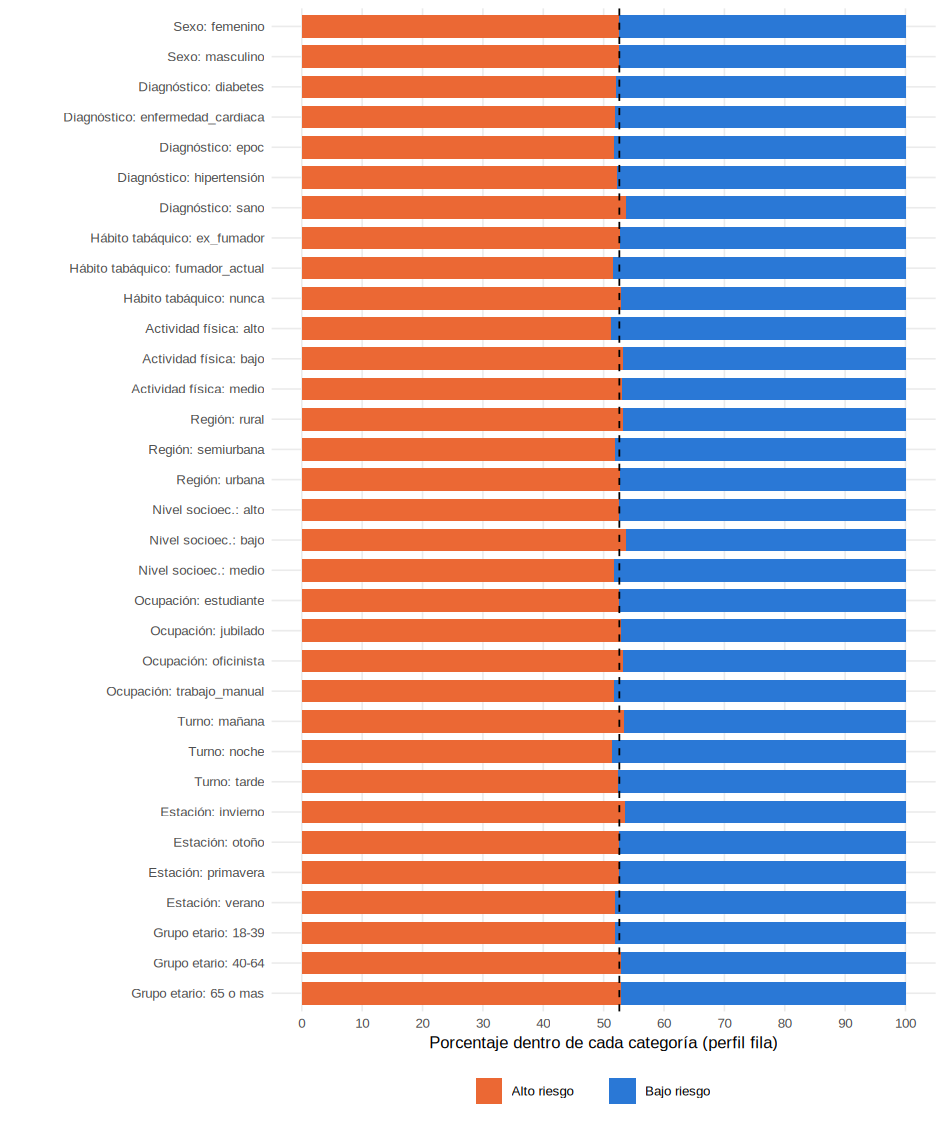

In [ ]:
nombre_var <- c(genero = "Sexo", diagnostico = "Diagnóstico", estado_fumador = "Hábito tabáquico",
                nivel_actividad_fisica = "Actividad física", region = "Región",
                nivel_socioeconomico = "Nivel socioec.", ocupacion = "Ocupación", turno = "Turno",
                estacion = "Estación", grupo_etario = "Grupo etario")
f7 <- contingencia
f7$etiqueta <- paste0(nombre_var[f7$variable], ": ", f7$categoria)
f7$etiqueta <- factor(f7$etiqueta, levels = rev(f7$etiqueta))
f7_largo <- rbind(data.frame(etiqueta = f7$etiqueta, riesgo = "Alto riesgo", pct = f7$pct_fila_alto),
                  data.frame(etiqueta = f7$etiqueta, riesgo = "Bajo riesgo", pct = 100 - f7$pct_fila_alto))
f7_largo$riesgo <- factor(f7_largo$riesgo, levels = c("Bajo riesgo", "Alto riesgo"))
g7 <- ggplot(f7_largo, aes(x = etiqueta, y = pct, fill = riesgo)) +
  geom_col(width = 0.75) +
  geom_hline(yintercept = base_global, linetype = "dashed", linewidth = 0.5) +
  coord_flip() +
  scale_y_continuous(breaks = seq(0, 100, 10)) +
  scale_fill_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO),
                    breaks = c("Alto riesgo", "Bajo riesgo")) +
  labs(x = NULL, y = "Porcentaje dentro de cada categoría (perfil fila)", fill = NULL) +
  tema + theme(legend.position = "bottom")
guardar(g7, "figura07_categoricas.png", 16, 19)

### 4.3. El caso de la glucosa: riesgo y diagnóstico son dimensiones distintas
La razón de correlación η² mide qué parte de la variabilidad de la glucosa explica el diagnóstico (suma de cuadrados entre grupos sobre suma de cuadrados total del ANOVA). Se compara con su capacidad para separar el riesgo y con su efecto sobre el KMO.

In [ ]:
modelo_glu <- aov(glucosa ~ diagnostico, data = d)
sc <- summary(modelo_glu)[[1]][["Sum Sq"]]
eta2 <- sc[1] / sum(sc)
cat("η² =", round(eta2, 3), "| η =", round(sqrt(eta2), 3), "\n\n")
cat("Glucosa media por diagnóstico:\n"); print(round(tapply(d$glucosa, d$diagnostico, mean), 2))
cat("\nGlucosa media: alto riesgo =", round(mean(d$glucosa[alto]), 2),
    "| bajo riesgo =", round(mean(d$glucosa[bajo]), 2),
    "| d =", round(magnitud_efecto(d$glucosa[alto], d$glucosa[bajo]), 3), "\n")
k6 <- kmo(cor(d[, c(discriminantes, "glucosa")]))
cat("KMO global con glucosa:", round(k6$global, 3),
    "| KMO de la glucosa:", round(k6$por_variable["glucosa"], 3), "\n")

η² = 0.679 | η = 0.824 

Glucosa media por diagnóstico:
           diabetes enfermedad_cardiaca                epoc        hipertensión                sano 
             178.73              100.04              100.54               99.99              100.10 

Glucosa media: alto riesgo = 114.71 | bajo riesgo = 114.87 | d = -0.004 
KMO global con glucosa: 0.562 | KMO de la glucosa: 0.358 


## 5. Estructura conjunta y componentes principales (informe, sección 7)
### 5.1. Tablas 6 y 7 — Covarianza y correlación
Las varianzas difieren en cuatro órdenes de magnitud, por eso el análisis multivariado se hace sobre la matriz de correlación.

In [ ]:
cat("===== VARIANZAS =====\n"); print(round(apply(d[, discriminantes], 2, var), 2))
cat("\n===== TABLA 6: MATRIZ DE COVARIANZA =====\n"); print(round(cov(d[, discriminantes]), 2))
matriz_cor <- cor(d[, discriminantes])
cat("\n===== TABLA 7: MATRIZ DE CORRELACIÓN =====\n"); print(round(matriz_cor, 3))

===== VARIANZAS =====
      trigliceridos          colesterol frecuencia_cardiaca          creatinina        imc_derivado 
            5155.17             1708.58              135.49                0.25               41.15 

===== TABLA 6: MATRIZ DE COVARIANZA =====
                    trigliceridos colesterol frecuencia_cardiaca creatinina imc_derivado
trigliceridos             5155.17    1362.43               99.36       7.44       186.62
colesterol                1362.43    1708.58               52.41       3.80       104.14
frecuencia_cardiaca         99.36      52.41              135.49       0.70         0.01
creatinina                   7.44       3.80                0.70       0.25         0.16
imc_derivado               186.62     104.14                0.01       0.16        41.15

===== TABLA 7: MATRIZ DE CORRELACIÓN =====
                    trigliceridos colesterol frecuencia_cardiaca creatinina imc_derivado
trigliceridos               1.000      0.459               0.119  

### 5.2. Figura 8 — Correlograma

Figura guardada: figura08_correlograma.png 


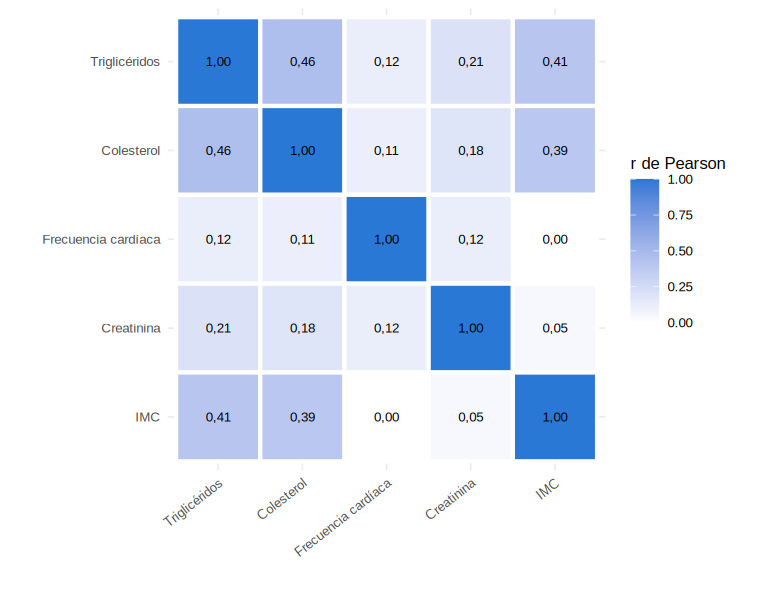

In [ ]:
cm <- as.data.frame(as.table(matriz_cor))
names(cm) <- c("v1", "v2", "r")
cm$v1 <- factor(etiquetas[as.character(cm$v1)], levels = etiquetas[discriminantes])
cm$v2 <- factor(etiquetas[as.character(cm$v2)], levels = rev(etiquetas[discriminantes]))
g8 <- ggplot(cm, aes(v1, v2, fill = r)) +
  geom_tile(colour = "white", linewidth = 1.2) +
  geom_text(aes(label = format(round(r, 2), decimal.mark = ",")), size = 2.8) +
  scale_fill_gradient(low = "white", high = BAJO, limits = c(0, 1)) +
  labs(x = NULL, y = NULL, fill = "r de Pearson") + tema +
  theme(axis.text.x = element_text(angle = 38, hjust = 1))
guardar(g8, "figura08_correlograma.png", 13, 10)

### 5.3. Observaciones atípicas multivariadas
Distancia de Mahalanobis de cada paciente al centro de la nube; umbral: raíz cuadrada del percentil 99,9 de una chi-cuadrado con 5 grados de libertad. Ningún atípico se excluye.

In [ ]:
cat("Umbral:", round(umbral_mahal, 3), "| Atípicos:", sum(d$d_mahalanobis > umbral_mahal),
    "| Distancia máxima:", round(max(d$d_mahalanobis), 2), "\n")
print(table(d$categoria_riesgo[d$d_mahalanobis > umbral_mahal]))

Umbral: 4.529 | Atípicos: 198 | Distancia máxima: 12.56 

alto_riesgo bajo_riesgo 
         97         101 


### 5.4. Adecuación de los datos: prueba de Bartlett e índice KMO

In [ ]:
p <- length(discriminantes); n <- nrow(d)
det_R <- det(matriz_cor)
chi2_bartlett <- -(n - 1 - (2 * p + 5) / 6) * log(det_R)
gl_bartlett <- p * (p - 1) / 2
cat("Bartlett: chi2 =", round(chi2_bartlett, 1), "| gl =", gl_bartlett,
    "| p =", signif(pchisq(chi2_bartlett, gl_bartlett, lower.tail = FALSE), 3),
    "| det(R) =", round(det_R, 4), "\n")
k5 <- kmo(matriz_cor)
cat("KMO global:", round(k5$global, 3), "\nKMO por variable:\n"); print(round(k5$por_variable, 3))

Bartlett: chi2 = 7620.4 | gl = 10 | p = 0 | det(R) = 0.5645 
KMO global: 0.672 
KMO por variable:
      trigliceridos          colesterol frecuencia_cardiaca          creatinina        imc_derivado 
              0.668               0.682               0.636               0.679               0.669 


### 5.5. Componentes principales (Tabla 8)
`prcomp` con `scale. = TRUE` trabaja sobre la matriz de correlación. Se retienen los autovalores mayores que uno (criterio de Kaiser). El signo de cada componente se fija para que valores altos indiquen mayor alteración.

In [ ]:
acp <- prcomp(d[, discriminantes], center = TRUE, scale. = TRUE)
autovalores <- acp$sdev^2
cat("Autovalores:", round(autovalores, 3), "\n")
cat("Varianza explicada (%):", round(100 * autovalores / p, 1), "\n")
cat("Varianza acumulada (%):", round(100 * cumsum(autovalores) / p, 1), "\n")
cat("Componentes retenidos por el criterio de Kaiser:", sum(autovalores > 1), "\n")

signo <- ifelse(colSums(acp$rotation) < 0, -1, 1)
if (acp$rotation["frecuencia_cardiaca", 2] * signo[2] < 0) signo[2] <- -signo[2]
rotacion <- sweep(acp$rotation, 2, signo, "*")
puntuaciones <- sweep(acp$x, 2, signo, "*")

cargas <- rotacion[, 1:3] %*% diag(acp$sdev[1:3])
colnames(cargas) <- c("CP1", "CP2", "CP3")
comunalidad <- rowSums(cargas[, 1:2]^2)
cat("\n===== TABLA 8: CARGAS FACTORIALES =====\n")
print(round(cbind(cargas, comunalidad_2CP = comunalidad), 3))
d$CP1 <- puntuaciones[, 1]
d$CP2 <- puntuaciones[, 2]

Autovalores: 1.94 1.069 0.874 0.58 0.537 
Varianza explicada (%): 38.8 21.4 17.5 11.6 10.7 
Varianza acumulada (%): 38.8 60.2 77.7 89.3 100 
Componentes retenidos por el criterio de Kaiser: 2 

===== TABLA 8: CARGAS FACTORIALES =====
                      CP1    CP2    CP3 comunalidad_2CP
trigliceridos       0.797 -0.058  0.010           0.639
colesterol          0.783 -0.087  0.036           0.620
frecuencia_cardiaca 0.241  0.744  0.611           0.613
creatinina          0.394  0.572 -0.694           0.483
imc_derivado        0.692 -0.420  0.130           0.655


### 5.6. Figura 9 — Gráfico de sedimentación

Figura guardada: figura09_sedimentacion.png 


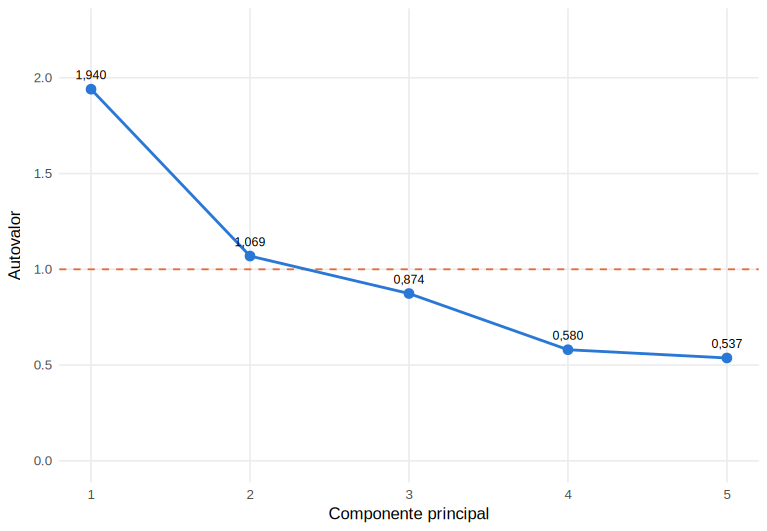

In [ ]:
f9 <- data.frame(cp = 1:p, autovalor = autovalores)
g9 <- ggplot(f9, aes(cp, autovalor)) +
  geom_hline(yintercept = 1, colour = ALTO, linetype = "dashed", linewidth = 0.5) +
  geom_line(colour = BAJO, linewidth = 0.8) +
  geom_point(colour = BAJO, size = 2.4) +
  geom_text(aes(label = format(round(autovalor, 3), decimal.mark = ",")), vjust = -1.1, size = 2.6) +
  scale_x_continuous(breaks = 1:p) + expand_limits(y = c(0, 2.25)) +
  labs(x = "Componente principal", y = "Autovalor") + tema
guardar(g9, "figura09_sedimentacion.png", 13, 9)

### 5.7. Figura 10 — Variables en el plano de los dos primeros componentes

Figura guardada: figura10_biplot.png 


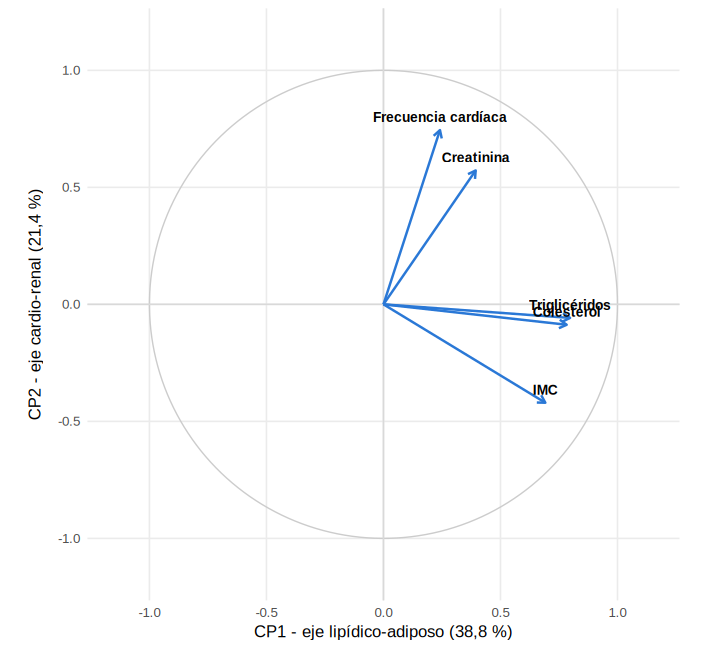

In [ ]:
f10 <- data.frame(variable = etiquetas[discriminantes], CP1 = cargas[, 1], CP2 = cargas[, 2])
circulo <- data.frame(x = cos(seq(0, 2 * pi, length.out = 200)),
                      y = sin(seq(0, 2 * pi, length.out = 200)))
eje_x <- paste0("CP1 - eje lipídico-adiposo (", con_coma(round(100 * autovalores[1] / p, 1)), " %)")
eje_y <- paste0("CP2 - eje cardio-renal (", con_coma(round(100 * autovalores[2] / p, 1)), " %)")
g10 <- ggplot() +
  geom_path(data = circulo, aes(x, y), colour = "grey80", linewidth = 0.4) +
  geom_hline(yintercept = 0, colour = "grey85") +
  geom_vline(xintercept = 0, colour = "grey85") +
  geom_segment(data = f10, aes(0, 0, xend = CP1, yend = CP2),
               arrow = arrow(length = unit(0.18, "cm")), colour = BAJO, linewidth = 0.7) +
  geom_text(data = f10, aes(CP1, CP2, label = variable), vjust = -0.8, size = 2.9, fontface = "bold") +
  coord_equal(xlim = c(-1.15, 1.15), ylim = c(-1.15, 1.15)) +
  labs(x = eje_x, y = eje_y) + tema
guardar(g10, "figura10_biplot.png", 12, 11)

### 5.8. Figura 11 — Los grupos de riesgo en el plano factorial
El ACP se calcula sin la etiqueta de riesgo, pero las cinco variables se eligieron justamente porque separan los grupos. Que los componentes también los separen es esperable y **no** constituye una validación independiente: esa evidencia la da el resultado de control (5.9). Lo que aporta el plano es **cómo** se separan los grupos.

CP1 : media alto = 0.812 | media bajo = -0.901 | d = 1.558 
CP2 : media alto = 0.298 | media bajo = -0.331 | d = 0.638 
Dispersión del CP1: alto = 1.367 | bajo = 0.69 | razón = 1.98 
Figura guardada: figura11_plano_factorial.png 


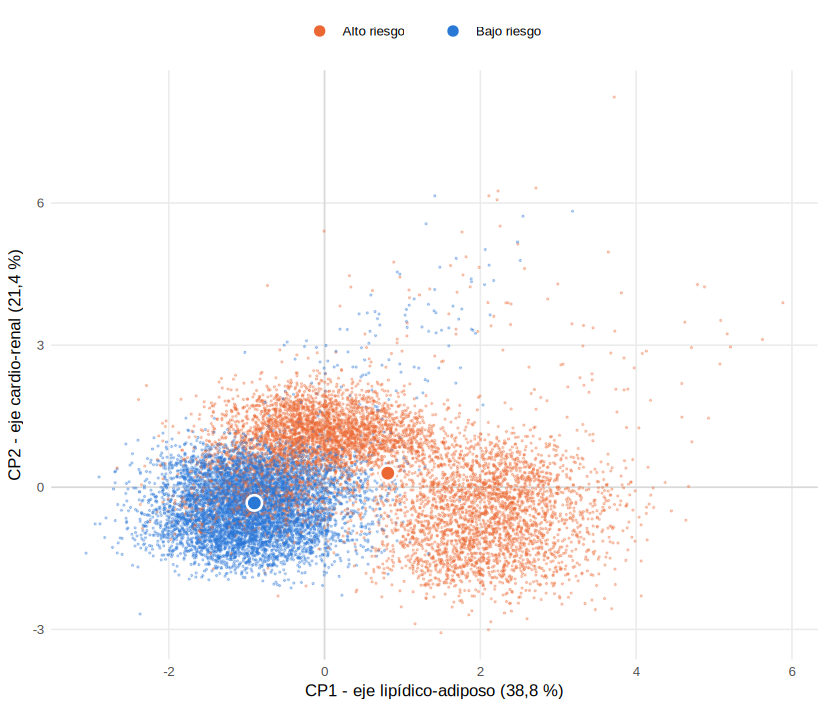

In [ ]:
for (k in c("CP1", "CP2")) {
  a <- d[[k]][alto]; b <- d[[k]][bajo]
  cat(k, ": media alto =", round(mean(a), 3), "| media bajo =", round(mean(b), 3),
      "| d =", round(magnitud_efecto(a, b), 3), "\n")
}
cat("Dispersión del CP1: alto =", round(sd(d$CP1[alto]), 3), "| bajo =", round(sd(d$CP1[bajo]), 3),
    "| razón =", round(sd(d$CP1[alto]) / sd(d$CP1[bajo]), 2), "\n")

f11 <- data.frame(CP1 = d$CP1, CP2 = d$CP2, riesgo = d$riesgo)
centroides <- aggregate(cbind(CP1, CP2) ~ riesgo, f11, mean)
g11 <- ggplot(f11, aes(CP1, CP2, colour = riesgo)) +
  geom_hline(yintercept = 0, colour = "grey85") +
  geom_vline(xintercept = 0, colour = "grey85") +
  geom_point(size = 0.35, alpha = 0.3) +
  geom_point(data = centroides, size = 3.6, stroke = 1.1, shape = 21,
             aes(fill = riesgo), colour = "white") +
  scale_colour_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  scale_fill_manual(values = c("Alto riesgo" = ALTO, "Bajo riesgo" = BAJO)) +
  guides(colour = guide_legend(override.aes = list(size = 2.6, alpha = 1)), fill = "none") +
  labs(x = eje_x, y = eje_y, colour = NULL) + tema + theme(legend.position = "top")
guardar(g11, "figura11_plano_factorial.png", 14, 12)

### 5.9. Resultado de control: ACP sin selección previa de variables
Se repite el ACP sobre catorce variables, elegidas sin mirar la etiqueta de riesgo. Si su primer componente vuelve a reunir triglicéridos, colesterol e IMC y separa los grupos, el eje lipídico-adiposo existe en los datos con independencia de la selección. Se muestra también por qué no se usan las dieciocho.

In [ ]:
R14 <- cor(d[, control_14])
k14 <- kmo(R14)
av14 <- sort(eigen(R14, symmetric = TRUE)$values, decreasing = TRUE)
kaiser14 <- sum(av14 > 1)
cat("ACP de", length(control_14), "variables: KMO =", round(k14$global, 3),
    "| Kaiser =", kaiser14, "componentes para",
    round(100 * cumsum(av14)[kaiser14] / length(control_14), 1), "% de la varianza\n")
cat("Autovalores:", round(av14, 3), "\n")

acp14 <- prcomp(d[, control_14], center = TRUE, scale. = TRUE)
cargas14 <- acp14$rotation[, 1] * acp14$sdev[1]
cat("\nCargas del CP1 de catorce variables, en valor absoluto:\n")
print(round(sort(abs(cargas14), decreasing = TRUE), 3))
cat("|d| entre grupos sobre el CP1 de catorce variables:",
    round(abs(magnitud_efecto(acp14$x[alto, 1], acp14$x[bajo, 1])), 3), "\n")

k18 <- kmo(cor(d[, todas_numericas]))
par18 <- k18$parcial; diag(par18) <- 0
pos <- which(abs(par18) == max(abs(par18)), arr.ind = TRUE)[1, ]
cat("\nCon las dieciocho: KMO =", round(k18$global, 3),
    "| mayor correlación parcial:", rownames(par18)[pos[1]], "-", colnames(par18)[pos[2]], "=",
    round(par18[pos[1], pos[2]], 3),
    "| IMC con peso =", round(par18["imc_derivado", "peso_kg"], 3), "\n")

ACP de 14 variables: KMO = 0.556 | Kaiser = 7 componentes para 60.5 % de la varianza
Autovalores: 1.998 1.208 1.139 1.086 1.023 1.011 1.005 0.975 0.963 0.961 0.922 0.77 0.573 0.367 

Cargas del CP1 de catorce variables, en valor absoluto:
              trigliceridos                  colesterol                imc_derivado                  creatinina                     glucosa 
                      0.842                       0.739                       0.649                       0.387                       0.332 
        frecuencia_cardiaca                        edad          saturacion_oxigeno        temperatura_corporal                 hemoglobina 
                      0.231                       0.076                       0.030                       0.024                       0.023 
 presion_arterial_sistolica                vfc_derivada presion_arterial_diastolica     frecuencia_respiratoria 
                      0.023                       0.018                       0.013 

## 6. El grupo de alto riesgo no es homogéneo (informe, sección 8)
### 6.1. Dispersión comparada entre grupos
No alcanza con comparar los centros: se comparan las dispersiones. El caso del IMC se mide además como distancia de cada paciente a la mediana de la base.

In [ ]:
disp <- data.frame()
for (v in discriminantes) {
  a <- d[[v]][alto]; b <- d[[v]][bajo]
  disp <- rbind(disp, data.frame(variable = v,
    sd_alto = round(sd(a), 2), sd_bajo = round(sd(b), 2), razon = round(sd(a) / sd(b), 2),
    min_alto = min(a), max_alto = max(a), min_bajo = min(b), max_bajo = max(b)))
}
print(disp)
cat("\nLevene en IMC: F =", round(tabla2$levene_F[tabla2$variable == "imc_derivado"], 1), "\n")

imc <- d$imc_derivado
cat("\nIMC por categoría y grupo de riesgo:\n"); print(table(d$imc_cat, d$categoria_riesgo))
cat("Bajo riesgo con IMC exactamente 30:", sum(imc[bajo] == 30), "\n")
cat("Alto riesgo fuera del intervalo [18,5; 30]:",
    round(100 * mean(imc[alto] < 18.5 | imc[alto] > 30), 1), "% | bajo riesgo:",
    sum(imc[bajo] < 18.5 | imc[bajo] > 30), "pacientes\n")
mediana_imc <- median(imc)
distancia_imc <- abs(imc - mediana_imc)
cat("Mediana del IMC:", mediana_imc, "| d del IMC:",
    round(magnitud_efecto(imc[alto], imc[bajo]), 3), "| d de la distancia a la mediana:",
    round(magnitud_efecto(distancia_imc[alto], distancia_imc[bajo]), 3), "\n")

             variable sd_alto sd_bajo razon min_alto max_alto min_bajo max_bajo
1       trigliceridos   66.20   49.03  1.35    65.60   546.10     40.2   359.70
2          colesterol   39.02   30.13  1.30   103.10   373.70     91.6   282.00
3 frecuencia_cardiaca   12.23    8.98  1.36    39.00   167.00     39.0   147.00
4          creatinina    0.45    0.50  0.91     0.47     7.32      0.4     7.25
5        imc_derivado    8.24    3.12  2.64    12.59    44.19     18.5    30.00

Levene en IMC: F = 8917.1 

IMC por categoría y grupo de riesgo:
           
            alto_riesgo bajo_riesgo
  bajo peso        2215           0
  normal           1144        3884
  sobrepeso         732        2433
  obesidad         2921           2
Bajo riesgo con IMC exactamente 30: 2 
Alto riesgo fuera del intervalo [18,5; 30]: 73.2 % | bajo riesgo: 0 pacientes
Mediana del IMC: 24.31 | d del IMC: 0.29 | d de la distancia a la mediana: 1.579 


### 6.2. Figura 12 — Distribución del IMC por grupo de riesgo
Intervalos de 0,5 cerrados a la izquierda, alineados con los cortes clínicos de 18,5, 25 y 30: ninguna barra mezcla pacientes de dos categorías.

Figura guardada: figura12_imc.png 


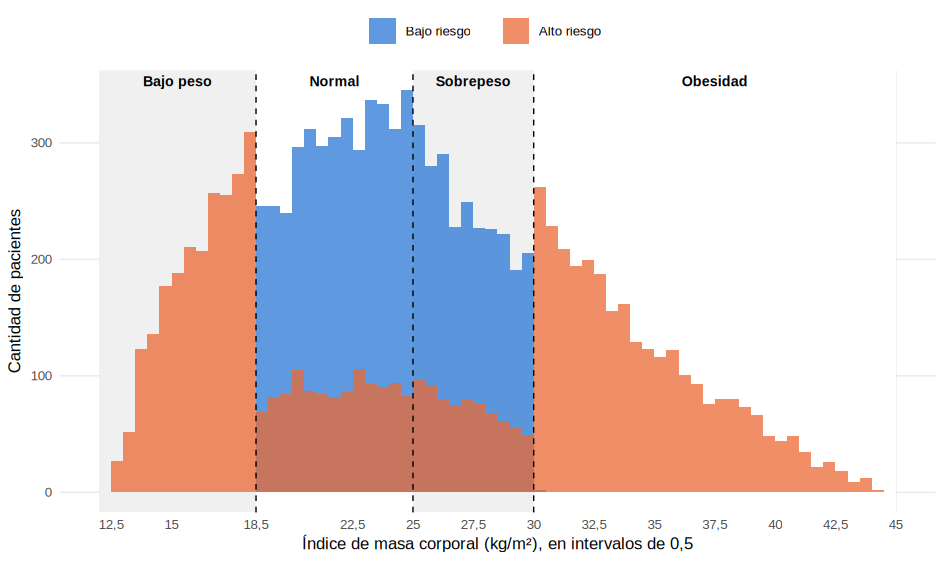

In [ ]:
bandas <- data.frame(xmin = c(12, 18.5, 25, 30), xmax = c(18.5, 25, 30, 45),
                     nombre = c("Bajo peso", "Normal", "Sobrepeso", "Obesidad"))
f12 <- data.frame(imc = imc, riesgo = factor(d$categoria_riesgo, levels = c("bajo_riesgo", "alto_riesgo"),
                                             labels = c("Bajo riesgo", "Alto riesgo")))
g12 <- ggplot(f12, aes(imc, fill = riesgo)) +
  geom_rect(data = bandas, aes(xmin = xmin, xmax = xmax, ymin = -Inf, ymax = Inf),
            inherit.aes = FALSE, fill = c("grey94", "white", "grey94", "white")) +
  geom_histogram(breaks = seq(12, 45, by = 0.5), closed = "left", alpha = 0.75, position = "identity") +
  geom_vline(xintercept = c(18.5, 25, 30), linetype = "dashed", linewidth = 0.4) +
  geom_text(data = bandas, aes(x = (xmin + xmax) / 2, y = Inf, label = nombre),
            inherit.aes = FALSE, vjust = 1.6, size = 3, fontface = "bold") +
  scale_x_continuous(breaks = c(12.5, 15, 18.5, 22.5, 25, 27.5, 30, 32.5, 35, 37.5, 40, 42.5, 45),
                     labels = con_coma) +
  scale_fill_manual(values = c("Bajo riesgo" = BAJO, "Alto riesgo" = ALTO)) +
  labs(x = "Índice de masa corporal (kg/m²), en intervalos de 0,5",
       y = "Cantidad de pacientes", fill = NULL) +
  tema + theme(legend.position = "top")
guardar(g12, "figura12_imc.png", 16, 9.5)

### 6.3. Tabla 9 — Tres perfiles dentro del alto riesgo
El alto riesgo se divide según los cortes clínicos del IMC: bajo peso (menos de 18,5), entre 18,5 y 30, y obesidad (30 o más). Para contrastar si los subgrupos difieren en las variables que no se usaron para definirlos se usa la prueba de Kruskal-Wallis, porque Levene evalúa primero si sus varianzas son iguales.

In [ ]:
perfil <- ifelse(bajo, "bajo_riesgo",
          ifelse(imc < 18.5, "alto_bajo_peso",
          ifelse(imc >= 30, "alto_obesidad", "alto_imc_18_30")))
perfil <- factor(perfil, levels = c("bajo_riesgo", "alto_bajo_peso", "alto_imc_18_30", "alto_obesidad"))
print(table(perfil))

centros <- aggregate(d[, discriminantes], by = list(perfil = perfil), FUN = mean)
tabla9 <- data.frame(perfil = centros$perfil, n = as.numeric(table(perfil)), round(centros[, discriminantes], 2))
print(tabla9)
write.csv(tabla9, "tabla9_perfiles.csv", row.names = FALSE)
cat("\nDesvío de la frecuencia cardíaca en el perfil IMC 18,5 a 30:",
    round(sd(d$frecuencia_cardiaca[perfil == "alto_imc_18_30"]), 2), "\n\n")

en_alto <- perfil != "bajo_riesgo"
perfil_alto <- droplevels(perfil[en_alto])
for (v in setdiff(discriminantes, "imc_derivado")) {
  x <- d[[v]][en_alto]
  lv <- levene(x, perfil_alto)
  kw <- kruskal.test(x ~ perfil_alto)
  cat(sprintf("%-20s Levene F = %7.1f (p = %.3g) | Kruskal-Wallis H = %7.1f (p = %.3g)\n",
              v, lv["F"], lv["p"], kw$statistic, kw$p.value))
}

perfil
   bajo_riesgo alto_bajo_peso alto_imc_18_30  alto_obesidad 
          6319           2215           1876           2921 
          perfil    n trigliceridos colesterol frecuencia_cardiaca creatinina imc_derivado
1    bajo_riesgo 6319        155.12     190.03               74.99       1.10        24.00
2 alto_bajo_peso 2215        204.35     214.97               79.52       1.43        16.26
3 alto_imc_18_30 1876        203.22     215.95               94.88       1.43        23.93
4  alto_obesidad 2921        285.74     259.55               79.51       1.44        34.32

Desvío de la frecuencia cardíaca en el perfil IMC 18,5 a 30: 4.1 

trigliceridos        Levene F =     8.3 (p = 0.000242) | Kruskal-Wallis H =  2802.2 (p = 0)
colesterol           Levene F =    24.4 (p = 2.66e-11) | Kruskal-Wallis H =  2215.2 (p = 0)
frecuencia_cardiaca  Levene F =  1363.1 (p = 0) | Kruskal-Wallis H =  2446.5 (p = 0)
creatinina           Levene F =     1.3 (p = 0.277) | Kruskal-Wallis H =     0.

### 6.4. Figura 13a — Diagramas de estrellas de los cuatro centros
Cada radio es una variable, reescalada entre el mínimo y el máximo de los cuatro centros (`stars()` con `scale = TRUE`). El primer radio (triglicéridos) apunta a la derecha y los demás siguen en sentido antihorario.

Figura guardada: figura13a_estrellas.png 


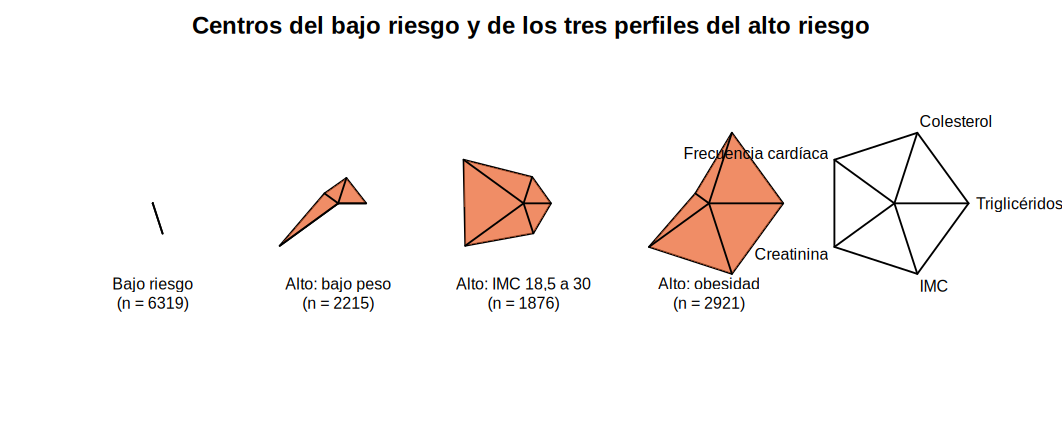

In [ ]:
M <- as.matrix(centros[, discriminantes])
nombres_perfil <- c("Bajo riesgo", "Alto: bajo peso", "Alto: IMC 18,5 a 30", "Alto: obesidad")
rownames(M) <- nombres_perfil
colnames(M) <- etiquetas[discriminantes]
dibujar_estrellas <- function() {
  stars(M, labels = paste0(nombres_perfil, "\n(n = ", as.numeric(table(perfil)), ")"),
        locations = cbind(c(1.2, 3.7, 6.2, 8.7), rep(1.4, 4)), len = 1,
        key.loc = c(11.2, 1.4), xlim = c(0, 12.6), ylim = c(-0.6, 2.6),
        col.stars = adjustcolor(c(BAJO, ALTO, ALTO, ALTO), alpha.f = 0.5),
        flip.labels = FALSE, cex = 0.8, lwd = 1.5,
        main = "Centros del bajo riesgo y de los tres perfiles del alto riesgo")
}
guardar_base("figura13a_estrellas.png", dibujar_estrellas, 18, 7.5)

### 6.5. Figura 13b — Caras de Chernoff de los cuatro centros
`faces()` asigna las columnas en orden a los rasgos: 1 alto de la cara, 2 ancho de la cara, 3 forma de la cara, 4 alto de la boca, 5 ancho de la boca, 6 sonrisa, y así hasta 15. Se pasan las cinco variables tres veces, en el orden triglicéridos, IMC, colesterol, creatinina y frecuencia cardíaca, para que los cinco rasgos principales queden fijados así: **alto de la cara = triglicéridos; ancho = IMC; forma = colesterol; alto de la boca = creatinina; ancho de la boca = frecuencia cardíaca**.

effect of variables:
 modified item       Var                    
 "height of face   " "trigliceridos"        
 "width of face    " "imc_derivado"         
 "structure of face" "colesterol"           
 "height of mouth  " "creatinina"           
 "width of mouth   " "frecuencia_cardiaca"  
 "smiling          " "trigliceridos.1"      
 "height of eyes   " "imc_derivado.1"       
 "width of eyes    " "colesterol.1"         
 "height of hair   " "creatinina.1"         
 "width of hair   "  "frecuencia_cardiaca.1"
 "style of hair   "  "trigliceridos.2"      
 "height of nose  "  "imc_derivado.2"       
 "width of nose   "  "colesterol.2"         
 "width of ear    "  "creatinina.2"         
 "height of ear   "  "frecuencia_cardiaca.2"
Figura guardada: figura13b_caras_chernoff.png 


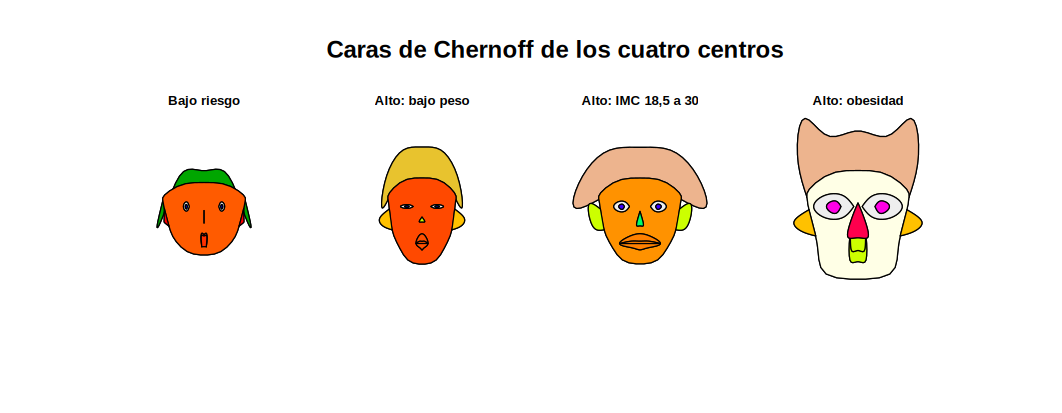

In [ ]:
orden_caras <- c("trigliceridos", "imc_derivado", "colesterol", "creatinina", "frecuencia_cardiaca")
M15 <- as.matrix(centros[, rep(orden_caras, 3)])
rownames(M15) <- nombres_perfil
mostrar_rasgos <- TRUE      # la tabla de rasgos se imprime una sola vez
dibujar_caras <- function() {
  faces(M15, labels = nombres_perfil, nrow.plot = 1, ncol.plot = 4, face.type = 1, cex = 1,
        print.info = mostrar_rasgos, main = "Caras de Chernoff de los cuatro centros")
  mostrar_rasgos <<- FALSE
}
guardar_base("figura13b_caras_chernoff.png", dibujar_caras, 18, 7)

## 7. Cierre
Todas las cifras del informe corregido salen de las salidas de este notebook y del archivo de limpieza.

In [ ]:
cat("Archivos generados:\n")
print(list.files(pattern = "^(tabla|figura).*\\.(csv|png)$"))
cat("\n===== ANÁLISIS COMPLETO =====\n")

Archivos generados:
 [1] "figura01_ranking.png"               "figura02_boxplots.png"              "figura03_dispersion_3d.png"        
 [4] "figura04_coordenadas_paralelas.png" "figura05a_perfiles.png"             "figura05b_radial.png"              
 [7] "figura06_qq_mahalanobis.png"        "figura07_categoricas.png"           "figura08_correlograma.png"         
[10] "figura09_sedimentacion.png"         "figura10_biplot.png"                "figura11_plano_factorial.png"      
[13] "figura12_imc.png"                   "figura13a_estrellas.png"            "figura13b_caras_chernoff.png"      
[16] "tabla2_comparacion.csv"             "tabla4_hotelling.csv"               "tabla5_contingencia.csv"           
[19] "tabla9_perfiles.csv"               

===== ANÁLISIS COMPLETO =====


In [ ]:
dir.create("outputs/tablas", recursive = TRUE, showWarnings = FALSE)
dir.create("outputs/figuras", recursive = TRUE, showWarnings = FALSE)

# Mover tablas y figuras a sus carpetas en R
archivos <- list.files(".")
for (f in archivos) {
  if (startsWith(f, "tabla") && endsWith(f, ".csv")) {
    file.rename(f, file.path("outputs/tablas", f))
  } else if (startsWith(f, "figura") && endsWith(f, ".png")) {
    file.rename(f, file.path("outputs/figuras", f))
  }
}

# Crear ZIP con todo
zip("hospital-4-outputs.zip", files = "outputs")
cat("ZIP creado: hospital-4-outputs.zip\n")

ZIP creado: hospital-4-outputs.zip
